In [64]:
import numpy as np
import pandas as pd

In [65]:
df = pd.read_csv("placement.csv")

In [66]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [68]:
df = df.iloc[: ,1:]

In [69]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [70]:
import matplotlib.pyplot as plt

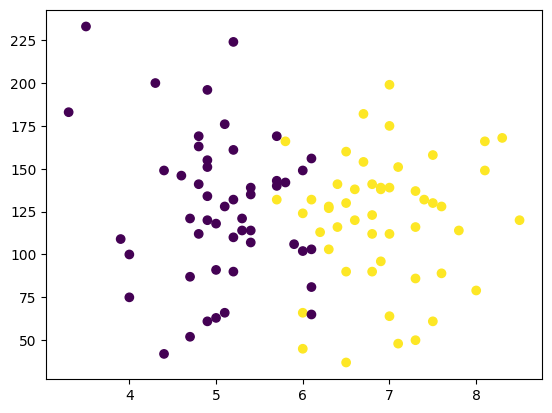

In [71]:
plt.scatter(df['cgpa'] , df['iq'], c = df['placement'])

In [72]:
x = df.iloc[: , 0:2]
y = df.iloc[: , -1]

In [73]:
x.head()

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0


In [74]:
y.head()

,placement
0,1
1,0
2,0
3,1
4,0


In [75]:
from sklearn.model_selection import train_test_split

In [76]:
x_train,x_test,y_train,y_test = train_test_split(x, y , test_size = 0.2)

In [77]:
x_train

,cgpa,iq
87,5.7,132.0
74,6.7,154.0
93,6.8,112.0
22,4.9,120.0
83,7.5,130.0
...,...,...
15,5.1,176.0
24,4.7,121.0
84,5.7,169.0
47,5.2,161.0


In [78]:
y_train

,placement
87,1
74,1
93,1
22,0
83,1
...,...
15,0
24,0
84,0
47,0


In [79]:
x_test

,cgpa,iq
31,3.9,109.0
13,6.4,116.0
53,8.3,168.0
77,7.3,50.0
92,5.2,110.0
25,5.0,91.0
60,6.9,139.0
33,6.0,149.0
67,5.0,118.0
1,5.9,106.0


In [80]:
from sklearn.preprocessing import StandardScaler

In [81]:
scaler = StandardScaler()

In [82]:
x_train = scaler.fit_transform(x_train)

In [83]:
x_train

array([[-0.26363607,  0.22289258],
       [ 0.593717  ,  0.75734892],
       [ 0.6794523 , -0.26297681],
       [-0.94951852, -0.06862905],
       [ 1.27959945,  0.17430564],
       [-0.94951852,  0.78164238],
       [ 1.27959945, -1.50194376],
       [-1.12098913, -1.72058499],
       [-0.6923126 , -0.79743314],
       [-0.6923126 ,  2.45789179],
       [ 0.16504047, -0.23868334],
       [-0.77804791,  0.12571871],
       [-0.60657729, -0.21438987],
       [ 0.93665822,  0.68446851],
       [ 1.27959945,  0.85452279],
       [ 0.6794523 ,  0.00425136],
       [-2.32128343,  1.46185953],
       [-1.12098913, -0.87031355],
       [-1.37819505, -1.96351968],
       [ 0.85092292, -1.42906335],
       [ 0.6794523 ,  0.44153381],
       [ 1.70827598, -1.06466131],
       [-1.46393036,  1.87484852],
       [-0.60657729, -0.04433558],
       [-0.00643015, -0.5059115 ],
       [ 1.79401129,  0.63588157],
       [ 0.07930516, -1.40476988],
       [ 1.10812884,  0.34435993],
       [-0.86378321,

In [84]:
x_test = scaler.transform(x_test)

In [85]:
x_test

array([[-1.80687159, -0.33585722],
       [ 0.33651108, -0.16580293],
       [ 1.9654819 ,  1.09745749],
       [ 1.10812884, -1.76917192],
       [-0.6923126 , -0.31156375],
       [-0.86378321, -0.77313967],
       [ 0.76518761,  0.39294687],
       [-0.00643015,  0.63588157],
       [-0.86378321, -0.11721599],
       [-0.09216545, -0.40873763],
       [ 0.07930516,  0.80593585],
       [-0.00643015,  0.02854483],
       [-0.94951852,  0.68446851],
       [-0.52084199, -0.38444416],
       [ 0.85092292,  1.26751178],
       [ 0.42224638,  0.17430564],
       [-0.00643015, -1.38047641],
       [-0.52084199,  0.39294687],
       [-1.20672444,  0.56300116],
       [ 0.593717  ,  1.43756606]])

In [86]:
from sklearn.linear_model import LogisticRegression

In [87]:
clf = LogisticRegression()

In [88]:
clf.fit(x_train, y_train)

LogisticRegression()

In [89]:
y_pred = clf.predict(x_test)

In [90]:
y_test

,placement
31,0
13,1
53,1
77,1
92,0
25,0
60,1
33,0
67,0
1,0


In [91]:
from sklearn.metrics import accuracy_score

In [92]:
accuracy_score(y_test,y_pred)

0.9

In [93]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

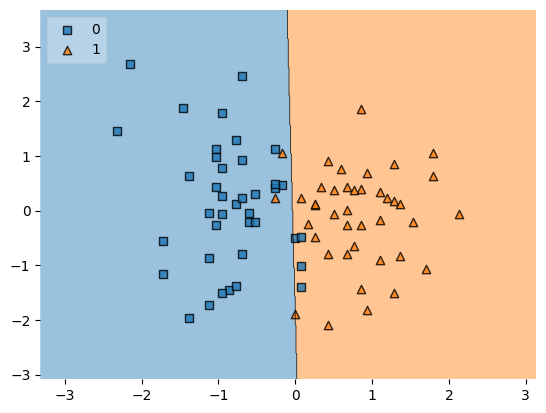

In [95]:
plot_decision_regions(x_train, y_train.values, clf=clf , legend = 2)

In [96]:
import pickle

In [97]:
pickle.dump(clf, open('placement.pkl','wb'))